# Векторные семантические модели

### Что такое дистрибутивная семантика?

> Дистрибуция — это позиционное распределение единиц языка, то есть сумма всех контекстов (окружений), в которых может встретиться тот или иной элемент (например, звук, морфема или слово).

>  Семантика — это раздел лингвистики, изучающий смысловое значение единиц языка: слов, словосочетаний и предложений. 

**Дистрибутивная семантика (distributional semantics)** — область компьютерной лингвистики, занимающаяся изучением смыслового значения слов или n-грамм через распределения в больших корпусах текстов.

Идея дистрибутивной семантики была популяризована английским лингвистом Джоном Фертом в 1950-е годы. Она следует так называемой **"дистрибутивной гипотезе"**: слова, встречающиеся в схожих контекстах, имеют близкие значения: *"you shall know a word by the company it keeps"*. 

Дистрибутивная семантика использует математические модели для представления слов в виде векторов в многомерном пространстве. Каждому слову соответствует уникальный набор чисел — вектор, который кодирует контексты употребления слова.

![Distributional_semantics.png](https://upload.wikimedia.org/wikipedia/commons/c/ce/Distributional_semantics.png)

Если это многомерное пространство, то что тогда кодирует каждое измерение? В самом простом виде — совместную встречаемость с какими-то словами в корпусе.

![](https://deepmachinelearning.ru/assets/images/sliding-window-on-text-4f4dc8c14f2c23f0734d54395fea686c.png)


### Матрица совместной встречаемости (матрица термин-термин)

Мы берём текст / коллецию текстов и проходимся по ним окном. Если слово попадает в окно нашего слова, то мы засчитываем это за совместное употребление.

![](https://encrypted-tbn0.gstatic.com/images?q=tbn:ANd9GcSw2clqh6H8npRJLiobC8vMl6BIUwdZghPSnCvKB_pO2WI3KldgeBvNSUc&s=10)

In [1]:
import numpy as np
import pandas as pd

def build_cooccurrence_df(texts, window_size):
    # Токенизация
    corpus = [text.lower().split() for text in texts]
    
    # Словарь уникальных слов
    vocab = sorted(set(word for sent in corpus for word in sent))
    
    # Создаём пустой DataFrame с нулями
    df = pd.DataFrame(0, index=vocab, columns=vocab, dtype=int)
    
    # Заполняем DataFrame
    for sent in corpus:
        for i, target in enumerate(sent):
            start = max(0, i - window_size)
            end = min(len(sent), i + window_size + 1)
            
            for j in range(start, end):
                if i != j:
                    neighbor = sent[j]
                    df.loc[target, neighbor] += 1
    
    return df

texts = [
    "Биба любит рыбу",
    "Боба любит рыбу",
    "Боба ест рыбу",
    "Боба ловит рыбу",
    "Биба ест рыбу"
]

df = build_cooccurrence_df(texts, window_size=1)
df

,биба,боба,ест,ловит,любит,рыбу
биба,0,0,1,0,1,0
боба,0,0,1,1,1,0
ест,1,1,0,0,0,2
ловит,0,1,0,0,0,1
любит,1,1,0,0,0,2
рыбу,0,0,2,1,2,0


In [2]:
# получим вектор слова

df.loc["ловит"].values

array([0, 1, 0, 0, 0, 1])

Раз слово имеет вектор, то мы можем считать близость между словами. 

In [ ]:
def cosine_similarity(word1, word2, df):
    v1 = df.loc[word1].values  # Берём вектор для слова
    v2 = df.loc[word2].values  
    
    # cкалярное произведение — сумма попарных произведений элементов векторов.
    dot_product = np.dot(v1, v2)
    
    # длины векторов — корень из суммы квадратов всех элементов
    norm_v1 = np.linalg.norm(v1)  
    norm_v2 = np.linalg.norm(v2)
    
    # косинусная близость — он же косинус угла
    cosine_sim = dot_product / (norm_v1 * norm_v2)
    
    # косинусное расстояние — это (1 - cos θ)
    # 0 <= cosine_distance <= 2
    return cosine_sim

# Использование
print(cosine_similarity('биба', 'боба', df))
print(cosine_similarity('ест', 'боба', df))
print(cosine_similarity('ловит', 'любит', df))
print(cosine_similarity('ест', 'любит', df))
print(cosine_similarity('биба', 'рыбу', df))

0.8164965809277259
0.0
0.8660254037844387
1.0000000000000002
0.9428090415820632


Ближайшие вектора — это **семантические ассоциаты**, т.е. такие слова (и словосочетания), которые не обязательно являются синонимами/антонимами, но употребляются в похожих контекстах. Часто их связывают гиперонимические отношения.

Как размер корпуса влияет на отношения между ближайшими векторами?

А размер окна?


### Меры расстояния между векторами

| Мера | Формула / смысл | Когда использовать |
|---|---|---|
| **Косинусная близость** | cos θ = (a · b) / (‖a‖ · ‖b‖) | Текстовые векторы (эмбеддинги), когда важна направленность, а не длина. Стандарт для word2vec/GloVe. |
| **Косинусное расстояние** | 1 − cos θ | То же, что косинусная близость, но в виде расстояния. |
| **Евклидово (L2)** | √( Σ (aᵢ − bᵢ)² ) | Когда важна абсолютная величина различий по всем измерениям. Чувствительна к длине вектора. |
| **Манхэттонское (L1)** | Σ \|aᵢ − bᵢ\| | Когда нужно более устойчивое к выбросам расстояние, чем L2. Часто в разреженных данных. |
| **Jaccard** | 1 − \|A ∩ B\| / \|A ∪ B\| | Бинарные векторы (присутствие/отсутствие признака), например, наборы тегов или one-hot-кодирование. |
| **Хэмминга** | Доля позиций, где векторы различаются | Бинарные или категориальные векторы одинаковой длины. |

Для плотных семантических векторов (word2vec, fastText, GloVe) почти всегда берут косинус. Для разреженных count-векторов — Евклид.

In [ ]:
from scipy.spatial.distance import euclidean, cityblock, jaccard, hamming
from scipy.spatial.distance import cosine as cosine_distance

v_biba = df.loc['биба'].values
v_boba = df.loc['боба'].values
v_est = df.loc['ест'].values
v_rybu = df.loc['рыбу'].values

print("Векторы (матрица совoccurrence):")
print("биба:", v_biba)
print("боба:", v_boba)
print("\nРасстояния между биба и боба:")
print("  Евклидово:", round(euclidean(v_biba, v_boba), 3))
print("  Манхэттенское:", round(cityblock(v_biba, v_boba), 3))
print("  Косинусное:", round(cosine_distance(v_biba, v_boba), 3))
print("  Jaccard (binarized):", round(jaccard(v_biba > 0, v_boba > 0), 3))

print("\nКосинусная близость (1 - расстояние) между ест и рыбу:",
      round(1 - cosine_distance(v_est, v_rybu), 3))


### Математические операции с векторами

Да, мы можем не только мерить расстояния между векторами, но и складывать/вычитать их.

Семантический калькулятор от [RusVectores](https://rusvectores.org/ru/calculator/).

Итак, мы построили свою первую семантическую модель! А зачем?..

### Какие задачи решают семантические модели?

- **Семантический поиск:** найти документы, близкие по значению запросу, даже если в них нет точных слов запроса. В т.ч. для рекомендательных систем.
- **Кластеризация и тематическое моделирование:** сгруппировать тексты по темам.
- **Классификация:** использовать эмбеддинги как признаки.
- **Обнаружение аномалий:** найти слово или документ, необычное для своего контекста.
- **Синхронные и диахронические исследования языка или идиолекта:** измерять сдвиг значений слов со временем или между корпусами.

_________
### PMI (Pointwise Mutual Information) 

PMI - это мера точечной взаимной информации. 
Сырая матрица совместной встречаемости имеет серьёзный недостаток: частые слова (например, «и», «в», «не») встречаются со многими другими словами просто потому, что они повсюду. Это зашумливает векторы и искажает оценку сходства.

**PMI** понижает веса общих (высокочастотных) пар и повышает веса тех пар, которые встречаются вместе чаще, чем следовало бы ожидать по случайности. 

![](https://blogger.googleusercontent.com/img/b/R29vZ2xl/AVvXsEiD_gIsTYCMxBIhZL7cBgWIiM8ME9lPe8VzclgyF4wrVdPJoEI9f__dgF9P5WWMHccVA0R23myuAIQCFeHFwgF250j9wiPy34U8osHBSHvYVejtlC5WJpFgRJZer9st3puQ6tsmNdbHiCqKw_O0g_vA5ZhxNzVD8irWkveRRb4aoUbjSH8LwkQq3HZd1A/s1600/PMI.png)

Стоит учитывать, что этот метод систематически завышает оценки совместной встречаемости для редких слов. На практике часто используют **PPMI** (Positive PMI), отсекая отрицательные значения до нуля.

In [ ]:
total = df.values.sum()
p_xy = df.values / total                       # P(x, y)
p_x = df.values.sum(axis=1, keepdims=True) / total   # P(x)
p_y = df.values.sum(axis=0, keepdims=True) / total   # P(y)

pmi = np.log2(p_xy / (p_x * p_y))
pmi = np.nan_to_num(pmi, nan=0.0, posinf=0.0, neginf=0.0)

pmi_df = pd.DataFrame(pmi, index=df.index, columns=df.columns)
pmi_df

Теперь векторы слов — это строки матрицы PMI. Посчитаем косинусную близость между ними и сравним с исходной матрицей соccurrence.

In [ ]:
def cosine_sim(v1, v2):
    return np.dot(v1, v2) / (np.linalg.norm(v1) * np.linalg.norm(v2))

print("=== Исходная матрица совместной встречаемости ===")
print("биба — боба:", round(cosine_sim(df.loc['биба'].values, df.loc['боба'].values), 3))
print("ест — рыбу:", round(cosine_sim(df.loc['ест'].values, df.loc['рыбу'].values), 3))
print("ловит — любит:", round(cosine_sim(df.loc['ловит'].values, df.loc['любит'].values), 3))

print("\n=== Матрица PMI (PPMI) ===")
print("биба — боба:", round(cosine_sim(pmi_df.loc['биба'].values, pmi_df.loc['боба'].values), 3))
print("ест — рыбу:", round(cosine_sim(pmi_df.loc['ест'].values, pmi_df.loc['рыбу'].values), 3))
print("ловит — любит:", round(cosine_sim(pmi_df.loc['ловит'].values, pmi_df.loc['любит'].values), 3))

____
### Word2Vec

Матрица совместной встречамости получается слишком большой и разреженной — заполненной нулями. И тем больше корпус, тем хуже. Математики придумали много способов «сжать» матрицу, оставив только нужные сведения: к таким методам относятся, например, сингулярное векторное разложение и случайное индексирование.

Настоящую революцию произвела представленная в 2013 году нейронная модель **word2vec**, разработанная Гуглом под руководством Томаша Миколова. 

Для желающих причаститься, посмотрите [диссертацию Томаша](https://www.fit.vut.cz/person/imikolov/public/rnnlm/thesis.pdf) и [статью о модели](https://arxiv.org/pdf/1301.3781).
[Статья от Системного Блока про Word2Vec](https://vk.com/@sysblok-word2vec-pokazhi-mne-svoi-kontekst-i-ya-skazhu-kto-ty)

Word2vec преобразует слова в векторы фиксированной длины (обычно 100–300 измерений), где семантически близкие слова, такие как «ходить» и «бежать», располагаются рядом в векторном пространстве. Это достигается с помощью двух архитектур:

| Архитектура | Задача | Когда лучше |
|---|---|---|
| **CBOW** (Continuous Bag of Words) | Предсказать целевое слово по окружающим контекстным словам | Быстрее обучается, лучше работает на частых словах и больших корпусах. |
| **Skip-gram** | Предсказать контекстные слова по целевому слову | Лучше для редких слов, работает эффективнее на малых и средних корпусах. |

Основная идея **skip-gram** заключается в том, чтобы предсказать контекстные слова (соседние слова) для заданного целевого слова в тексте. Модель обучается на парах вида (целевое слово, контекстное слово), где контекстные слова находятся в определённом окне вокруг целевого слова.
Например, для предложения "Кошка сидит на ковре" с окном размера 2:

CBOW: вход — контекст `["Кот", "спит", "на", "ковре"]` (без целевого слова), выход — целевое слово.
Если целевое слово «спит», модель получает на вход соседей и пытается предсказать «спит».

Skip-gram: вход — целевое слово «спит», выход — все слова из контекста `["Кот", "на", "ковре"]`. Модель учится предсказывать окружение слова.

### Как обучается (вкратце)

1. Все слова изначально получают **случайные векторы** (до обучения они бесполезны — любые слова равноудалённы).
2. Модель проходит по корпусу окном, составляя пары (цель, контекст).
3. Для каждой пары предсказывает вероятность контекстного слова через softmax по всем словам словаря.
4. Ошибка распространяется назад, векторы корректируются так, чтобы связанные слова приближались.
5. Для ускорения используют **Negative Sampling**: вместо полного softmax выбирают несколько «отрицательных» (неподходящих) слов и отдаляют их от настоящего контекста.


После обучения модель хранит **эмбеддинги** — вектора для каждого слова из словаря.

Сами векторные значения не имеют прямого лингвистического смысла изолированно: смысл возникает из относительного расположения векторов друг относительно друга.



> Давайте подумаем, в чём состоят ограничения модели Word2Vec.

In [ ]:
#pip install scipy==1.12
import gensim

tiny_corpus = [
    "кот спит на ковре".split(),
    "кот ест рыбу".split(),
    "собака спит на ковре".split(),
    "собака ест мясо".split(),
    "рыба плавает в реке".split(),
    "кот ловит рыбу".split(),
    "собака лает".split(),
]

# CBOW (sg=0): предсказание слова по контексту
model_cbow = gensim.models.Word2Vec(
    tiny_corpus, vector_size=10, window=2, min_count=1, sg=0, epochs=200, seed=42
)

# Skip-gram (sg=1): предсказание контекста по слову
model_sg = gensim.models.Word2Vec(
    tiny_corpus, vector_size=10, window=2, min_count=1, sg=1, epochs=200, seed=42
)

print("CBOW:  ближайшие к 'кот':", model_cbow.wv.most_similar('кот', topn=5))
print("Skip-gram: ближайшие к 'кот':", model_sg.wv.most_similar('кот', topn=5))
print()
print("CBOW:  ближайшие к 'рыба':", model_cbow.wv.most_similar('рыба', topn=5))
print("Skip-gram: ближайшие к 'рыба':", model_sg.wv.most_similar('рыба', topn=5))

CBOW:  ближайшие к 'кот': [('реке', 0.30844607949256897), ('плавает', 0.3039127588272095), ('ловит', 0.2690768539905548), ('рыба', 0.21373051404953003), ('мясо', 0.128867506980896)]
Skip-gram: ближайшие к 'кот': [('реке', 0.31203022599220276), ('плавает', 0.308817982673645), ('ловит', 0.2676585018634796), ('рыба', 0.21660780906677246), ('мясо', 0.12903159856796265)]

CBOW:  ближайшие к 'рыба': [('реке', 0.6545353531837463), ('собака', 0.39966487884521484), ('рыбу', 0.30097344517707825), ('ковре', 0.23834756016731262), ('ловит', 0.2287944257259369)]
Skip-gram: ближайшие к 'рыба': [('реке', 0.6580386757850647), ('собака', 0.4071579575538635), ('рыбу', 0.3028191924095154), ('ковре', 0.2393108308315277), ('ловит', 0.22642885148525238)]


## Эксперимент

Сегодня мы попробуем выявить особенности семантического окружения некоторых понятий в корпусах текстов славянофилов и западников.


In [ ]:
from pymorphy3 import MorphAnalyzer
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
import re
import os
from tqdm import tqdm
morph = MorphAnalyzer()
stopwords_ru = set(stopwords.words('russian'))

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/requests/__init__.py:113: RequestsDependencyWarning: urllib3 (1.26.20) or chardet (7.4.3)/charset_normalizer (3.4.0) doesn't match a supported version!
  warnings.warn(


In [ ]:
!wget "https://github.com/Darya-Galkina/MiniDegree/blob/main/seminar_6_dist_sem/aksakov.zip" -O aksakov.zip
!unzip aksakov.zip

!wget "https://github.com/Darya-Galkina/MiniDegree/blob/main/seminar_6_dist_sem/slavs.zip" -O aksakov.zip
!unzip slavs.zip

!wget "https://github.com/Darya-Galkina/MiniDegree/blob/main/seminar_6_dist_sem/belinsky.zip" -O aksakov.zip
!unzip belinsky.zip

In [4]:
slavs = []

paths = ['slavs/', 'aksakov/']
for path in paths:
    for filename in tqdm(os.listdir(path)):
        if "txt" in filename:
            with open(path + filename, encoding='utf-8') as txt:
                text = txt.read()
                text = re.sub(r'\n', ' ', text)
                text = re.sub(r'[^А-Яа-я -]', '', text.lower())
                text = [str(morph.parse(token)[0].normal_form) + '_' + str(morph.parse(token)[0].tag.POS) for token in word_tokenize(text) if token not in stopwords_ru and len(token) > 2]
                slavs.append(text)     

100%|██████████| 616/616 [00:41<00:00, 14.77it/s]


In [5]:
zapad = []
path = 'belinsky/'

for filename in tqdm(os.listdir(path)):
    if "txt" in filename:
        with open(path + filename, encoding='utf-8') as txt:
            text = txt.read()
            text = re.sub(r'\n', ' ', text)
            text = re.sub(r'[^А-Яа-я -]', '', text.lower())
            text = [str(morph.parse(token)[0].normal_form) + '_' + str(morph.parse(token)[0].tag.POS) for token in word_tokenize(text) if token not in stopwords_ru and len(token) > 2]
            zapad.append(text)  

100%|██████████| 343/343 [00:28<00:00, 11.94it/s]


In [6]:
w2v_slavs = gensim.models.Word2Vec(slavs, vector_size=300, window=10, min_count=5, sg=0, epochs=5) 
w2v_zapad = gensim.models.Word2Vec(zapad, vector_size=300, window=10, min_count=5, sg=0, epochs=5) 

In [ ]:
# вот так модели можно сохранить, чтобы не обучать каждый раз заново
w2v_slavs.wv.save_word2vec_format('w2v_slavs.bin', binary=True) 
w2v_zapad.wv.save_word2vec_format('w2v_zapad.bin', binary=True) 

In [7]:
print(len(w2v_slavs.wv))
print(len(w2v_zapad.wv))

15179
5919


In [8]:
w2v_slavs.wv.most_similar('дом_NOUN')

[('наверх_ADVB', 0.8574374318122864),
 ('обедать_VERB', 0.8447378873825073),
 ('гость_NOUN', 0.8342153429985046),
 ('домой_ADVB', 0.8288753628730774),
 ('генерал-губернаторский_ADJF', 0.8244245648384094),
 ('унковский_ADJF', 0.8204848170280457),
 ('маленький_ADJF', 0.8144556283950806),
 ('встретить_VERB', 0.8136794567108154),
 ('сидеть_VERB', 0.8070169687271118),
 ('съезжаться_VERB', 0.8058531284332275)]

In [ ]:
# можно указывать то, с каким словом не нужно искать ассоциаты
w2v_slavs.wv.most_similar('письмо_NOUN', negative=['почта_NOUN'])

[('добрый_ADJF', 0.6777520179748535),
 ('уважать_VERB', 0.6489545702934265),
 ('искренний_ADJF', 0.6442770957946777),
 ('сердце_NOUN', 0.6400866508483887),
 ('помнить_VERB', 0.6159607768058777),
 ('благородный_ADJF', 0.5882750153541565),
 ('родственный_ADJF', 0.5865046381950378),
 ('семейство_NOUN', 0.5831992626190186),
 ('молчаливый_ADJF', 0.578116238117218),
 ('искренно_ADVB', 0.569782018661499)]

In [10]:
# кстати, можно подавать сразу несколько слов, чтобы искать похожие.
print(w2v_slavs.wv.most_similar(['письмо_NOUN', 'депеша_NOUN'], topn=20))

[('писать_PRTS', 0.9205387234687805), ('послать_PRTF', 0.9109935760498047), ('заблагорассудить_VERB', 0.8872849345207214), ('пакет_NOUN', 0.8840474486351013), ('послать_PRTS', 0.8799744844436646), ('писать_PRTF', 0.8758565783500671), ('почтамт_NOUN', 0.8738839030265808), ('повторить_PRTS', 0.8573963046073914), ('якутск_NOUN', 0.8527110815048218), ('несвоевременно_ADVB', 0.8518242239952087), ('адресовать_PRTS', 0.8503440022468567), ('адресовать_PRTF', 0.8481067419052124), ('ермолов_NOUN', 0.8410841226577759), ('отправить_PRTF', 0.8393076062202454), ('плетнёв_NOUN', 0.8365814685821533), ('помшаль_NOUN', 0.8358102440834045), ('распорядиться_VERB', 0.8328235745429993), ('незапечатанный_ADJF', 0.8282514810562134), ('залежаться_VERB', 0.8265618681907654), ('распорядиться_INFN', 0.8261407017707825)]


Процесс обучения можно настраивать

**vector_size** — размер вектора (по умолчанию 100, в среднем ставят 100-1000);  
**min_count** — минимальная частота слова в корпусе (по умолчанию 5);  
**max_vocab_size** — максимальный размер словаря (по умолчанию ограничений нет);  
**window** — размер окна (по умолчанию 5);  
**epochs** — количество эпох (по умолчанию 5, полных итераций по корпусу);  

*class gensim.models.word2vec.Word2Vec(sentences=None, corpus_file=None, vector_size=100, alpha=0.025, window=5, min_count=5, max_vocab_size=None, sample=0.001, seed=1, workers=3, min_alpha=0.0001, sg=0, hs=0, negative=5, ns_exponent=0.75, cbow_mean=1, hashfxn=, epochs=5, null_word=0, trim_rule=None, sorted_vocab=1, batch_words=10000, compute_loss=False, callbacks=(), comment=None, max_final_vocab=None, shrink_windows=True)*

Также есть атрибут sg, в котором выбирается модель скипграмм или CBOW. 0 — CBOW, 1 - skipgram (по умолчанию CBOW).

### Как отобразить многомерное пространство на плоскости?

Для визуализации нам понадобится алгоритм снижения размерности. Он используется, чтобы вложить многомерное пространство в двух- или трехмерное. 

In [11]:
freq_tokens_tagged = w2v_slavs.wv.key_to_index  
words_tagged = list(freq_tokens_tagged.keys())
words_nouns = [tok for tok in words_tagged if tok[-4:] == 'NOUN'][:50]
print(words_nouns)

['письмо_NOUN', 'день_NOUN', 'год_NOUN', 'дело_NOUN', 'человек_NOUN', 'время_NOUN', 'москва_NOUN', 'деньга_NOUN', 'отесинька_NOUN', 'бог_NOUN', 'маменька_NOUN', 'петербург_NOUN', 'час_NOUN', 'слово_NOUN', 'константин_NOUN', 'жизнь_NOUN', 'друг_NOUN', 'дом_NOUN', 'случай_NOUN', 'неделя_NOUN', 'место_NOUN', 'брат_NOUN', 'душа_NOUN', 'сестра_NOUN', 'дорога_NOUN', 'почта_NOUN', 'месяц_NOUN', 'часть_NOUN', 'город_NOUN', 'статья_NOUN', 'стих_NOUN', 'сторона_NOUN', 'книга_NOUN', 'рубль_NOUN', 'какъ_NOUN', 'работа_NOUN', 'право_NOUN', 'пора_NOUN', 'мысль_NOUN', 'ручка_NOUN', 'князь_NOUN', 'мера_NOUN', 'достоевский_NOUN', 'роман_NOUN', 'россия_NOUN', 'вамъ_NOUN', 'вид_NOUN', 'суббота_NOUN', 'народ_NOUN', 'общество_NOUN']


In [12]:
word_vectors = np.array([w2v_slavs.wv[word] for word in words_nouns])

from sklearn.manifold import TSNE 
tsne = TSNE(n_components=2, random_state=17, perplexity=30)
tsne_vectors = tsne.fit_transform(word_vectors)
tsne_vectors[:10]

array([[-6.4333787 ,  1.7952262 ],
       [-5.5766706 ,  2.2204106 ],
       [-4.5431943 ,  1.1908096 ],
       [-4.3807034 ,  1.4064925 ],
       [-3.3132482 ,  0.9589646 ],
       [-4.7349343 ,  1.6511872 ],
       [-5.5867085 ,  1.1974648 ],
       [-5.0038223 , -0.65636426],
       [-7.104548  ,  1.1493367 ],
       [-3.8050656 , -0.9395831 ]], dtype=float32)

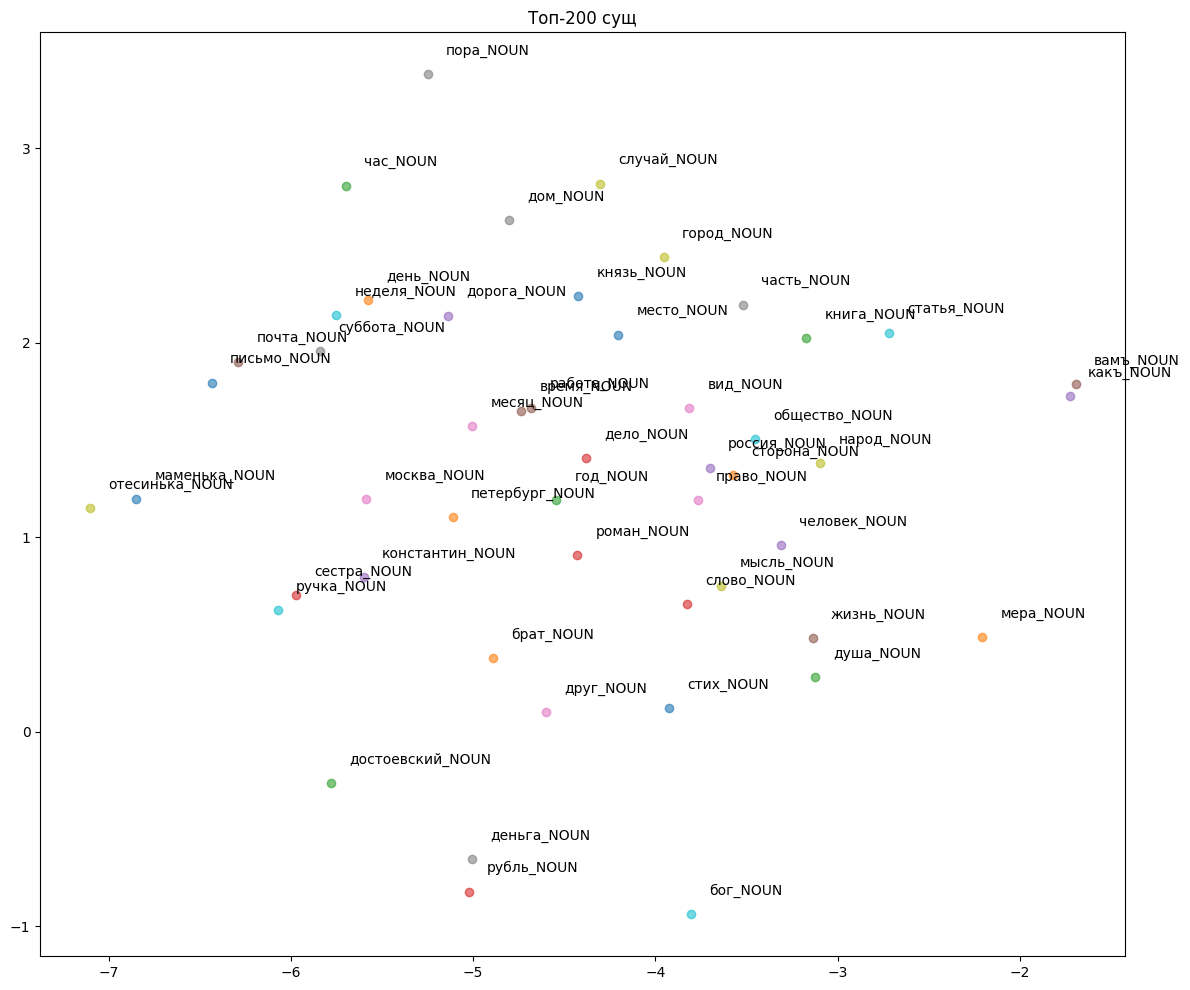

In [13]:
import matplotlib.pyplot as plt
plt.figure(figsize=(14, 12))
for i, word in enumerate(words_nouns):
    x, y = tsne_vectors[i, :]
    plt.scatter(x, y, marker='o', alpha=0.6)
    plt.text(x + 0.1, y + 0.1, word, fontsize=10)

plt.title("Топ-200 сущ")
plt.show()

То же самое, но с красивой библиотекой plotly.

In [129]:
import plotly.graph_objects as go

fig = go.Figure()
for i, word in enumerate(words_nouns):
    x, y = tsne_vectors[i, :]
    fig.add_trace(
        go.Scatter(
            x=[x],
            y=[y],
            mode="markers+text",
            text=[word],
            textposition="top center",
            marker=dict(size=8, opacity=0.7))
    )

fig.update_layout(
    title="Топ-200 сущ",
    showlegend=False,
    hovermode="closest",
    width=1000,
    height=800,
    template="plotly_white"
)
fig.show()

Теперь посмотрим на окружение отдельных слов.

In [14]:
top_rus = [tupl[0] for tupl in w2v_slavs.wv.most_similar('русский_ADJF', topn=20)]
print(top_rus)

['беседа_NOUN', 'оглавление_NOUN', 'курзал_NOUN', 'поговорка_NOUN', 'сень_NOUN', 'иностранный_ADJF', 'закидать_VERB', 'хвалёный_ADJF', 'французский_ADJF', 'распространить_INFN', 'публика_NOUN', 'язык_NOUN', 'беспечность_NOUN', 'державин_NOUN', 'европа_NOUN', 'поучиться_INFN', 'литература_NOUN', 'примирить_VERB', 'изгой_NOUN', 'критика_NOUN']


In [15]:
top_rus.append('русский_ADJF')
vectors = [w2v_slavs.wv[word] for word in top_rus]
vectors = np.array(vectors)
print(vectors)

[[-3.1411156e-01  3.8653159e-01  1.3827172e-01 ...  2.2604643e-01
   2.0486760e-01 -2.8291011e-01]
 [-6.5102987e-02  3.9219357e-02  4.9607579e-02 ...  5.0343957e-02
   5.0601441e-02 -3.6864724e-02]
 [-4.3194275e-02  2.1544136e-02  3.6803842e-02 ...  1.1852861e-02
   1.7442714e-02  1.3951838e-03]
 ...
 [-1.7141150e-03  2.6380826e-02  1.4819040e-02 ...  3.9025061e-02
   4.1738283e-03 -1.2764892e-02]
 [-2.6463902e-01  3.7493569e-01  3.2911712e-01 ...  2.8042048e-01
   2.9786915e-01 -1.9331998e-01]
 [-1.8044546e+00  6.6284287e-01  8.1558533e-02 ...  9.3588597e-01
   2.4537392e-02 -3.2020327e-01]]


In [16]:
tsne = TSNE(n_components=2, random_state=42, perplexity=5)
vectors_2d = tsne.fit_transform(np.array(vectors))

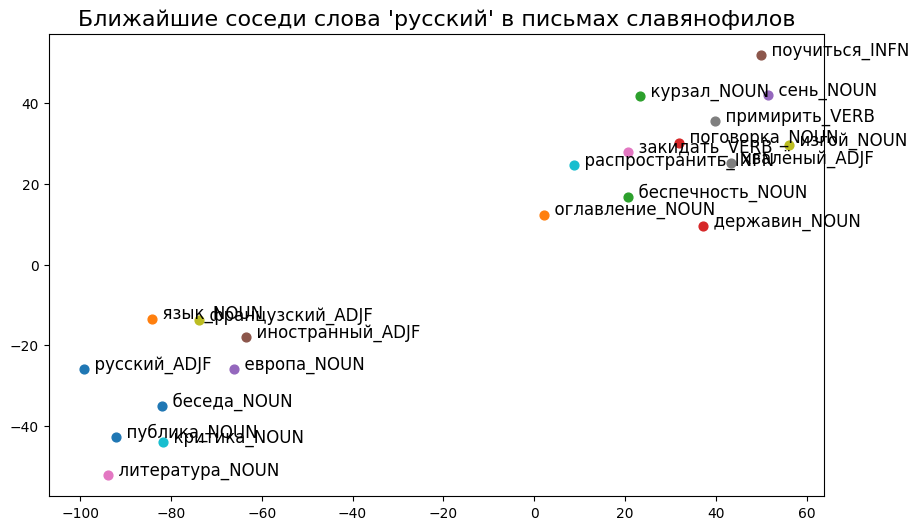

In [17]:
plt.figure(figsize=(10, 6))
for i, word in enumerate(top_rus):
    plt.scatter(vectors_2d[i, 0], vectors_2d[i, 1], s=40)
    plt.annotate("  "+ word, (vectors_2d[i, 0], vectors_2d[i, 1]), fontsize=12)
plt.title("Ближайшие соседи слова 'русский' в письмах славянофилов", fontsize=16)
plt.show()

### Задание
А теперь посмотрите на соседей любого слова в модели, построенной на корпусе писем Билинского.

______
Существуют уже обученные на больших корпусах модели, давайте посмотрим на [эмбеддинги от RusVectores](https://rusvectores.org/en/models/). Скачайте модель ruwikiruscorpora_upos_cbow_300_10_2021.

In [18]:
model = gensim.models.KeyedVectors.load_word2vec_format('model.bin', binary=True)

In [19]:
model.most_similar('любить_VERB')

[('обожать_VERB', 0.7903730273246765),
 ('нравиться_VERB', 0.7554476857185364),
 ('ненавидеть_VERB', 0.682483971118927),
 ('полюбить_VERB', 0.6718093752861023),
 ('любить_ADJ', 0.630898654460907),
 ('любимый_VERB', 0.6209321618080139),
 ('любить_NOUN', 0.6193422675132751),
 ('любовь_NOUN', 0.612057089805603),
 ('любимый_ADJ', 0.6120219230651855),
 ('уважать_VERB', 0.6057565808296204)]

In [ ]:
# а так можно вытащить ближайшего соседа
model.most_similar('любить_VERB')[0][0]

'обожать_VERB'

### Зачем нужны методы снижения размерности?

В высокоразмерном пространстве (сотни или тысячи измерений) возникает парадокс: **расстояния между почти всеми парами точек становятся почти одинаковыми**. Точки оказываются «равноудалёнными» друг от друга, и понятие «близость» теряет смысл — разница между ближайшим и дальним соседом становится ничтожной.

### Методы снижения размерности: основные алгоритмы

| Метод | Механизм | Когда использовать |
|---|---|---|
| **PCA** (Principal Component Analysis) | Находит ортогональные оси максимальной дисперсии, проецирует данные на них ![image2.gif](https://substackcdn.com/image/fetch/$s_!_xRi!,f_auto,q_auto:good,fl_progressive:steep/https%3A%2F%2Fsubstack-post-media.s3.amazonaws.com%2Fpublic%2Fimages%2Fa00f3301-9f4f-4de3-a5bb-dc8866c1afc4_819x580.png)| Линейная зависимость, нужно сохранить максимальную дисперсию, интерпретируемость осей. |
| **t-SNE** | Моделирует вероятности соседей в высоком и низком измерении, минимизирует расхождение ![image2.gif](https://storage.googleapis.com/gweb-research2023-media/original_images/00b43fa02b373e51c90eb7a781520f3d-image2.gif)| Визуализация кластеров в 2D/3D, исследование локальной структуры.|
| **UMAP** | Построение взвешенного графа соседей и его оптимизация в пространстве с маньшим количеством измерений ![](https://biostatsquid.com/wp-content/uploads/2025/03/Slide77.png) | Лучше сохраняет глобальную структуру. Лучше работает с вложенными структурами. |